# 01 — Exploratory data analysis (nn5 track)

Thin notebook: all logic lives in `atm_cash_optimizer.analysis` and `sql/eda_queries.sql`.
Run `python -m atm_cash_optimizer.data.ingest` and `python -m atm_cash_optimizer.analysis.clustering` first.

In [1]:
import holidays

from atm_cash_optimizer.analysis import profiles
from atm_cash_optimizer.analysis.clustering import WEEKDAYS, machine_features
from atm_cash_optimizer.io import DEFAULT_DATA_DIR, query, read_sql_queries, read_table

df = read_table("nn5_daily")
clusters = read_table("machine_clusters")
df.head()

,machine_id,date,withdrawals_raw,withdrawals_lkr,is_imputed
0,NN5_001,1996-03-18,13.407029,6.703515e+05,False
1,NN5_001,1996-03-19,14.725057,7.362528e+05,False
2,NN5_001,1996-03-20,20.564059,1.028203e+06,False
3,NN5_001,1996-03-21,34.708050,1.735402e+06,False
4,NN5_001,1996-03-22,26.629819,1.331491e+06,False


## SQL queries (DuckDB)

In [2]:
queries = read_sql_queries(DEFAULT_DATA_DIR.parent / "sql" / "eda_queries.sql")
results = {name: query(sql) for name, sql in queries.items()}
for name, result in results.items():
    print(f"--- {name}")
    display(result)

--- weekday_averages


,iso_weekday,weekday,avg_withdrawals_lkr
0,1,Monday,710419.0
1,2,Tuesday,752523.0
2,3,Wednesday,980504.0
3,4,Thursday,1386378.0
4,5,Friday,1218961.0
5,6,Saturday,637039.0
6,7,Sunday,763259.0


--- monthly_totals


,month,days,total_withdrawals_lkr
0,1996-03-01,14,1.315407e+09
1,1996-04-01,30,2.852651e+09
2,1996-05-01,31,3.119356e+09
3,1996-06-01,30,2.935470e+09
4,1996-07-01,31,3.081205e+09
5,1996-08-01,31,3.130005e+09
6,1996-09-01,30,2.915546e+09
7,1996-10-01,31,3.110593e+09
8,1996-11-01,30,2.957490e+09
9,1996-12-01,31,3.356974e+09


--- top_volatility_machines


,machine_id,avg_withdrawals_lkr,cv
0,NN5_052,1274027.0,0.603
1,NN5_037,669542.0,0.602
2,NN5_030,1027950.0,0.577
3,NN5_073,780537.0,0.573
4,NN5_006,901215.0,0.552
5,NN5_088,661384.0,0.549
6,NN5_016,1098107.0,0.546
7,NN5_064,596947.0,0.544
8,NN5_033,966929.0,0.530
9,NN5_085,684019.0,0.526


--- month_end_vs_mid_month


,period,machine_days,avg_withdrawals_lkr
0,mid_month,70485,909569.0
1,month_end,17316,969039.0


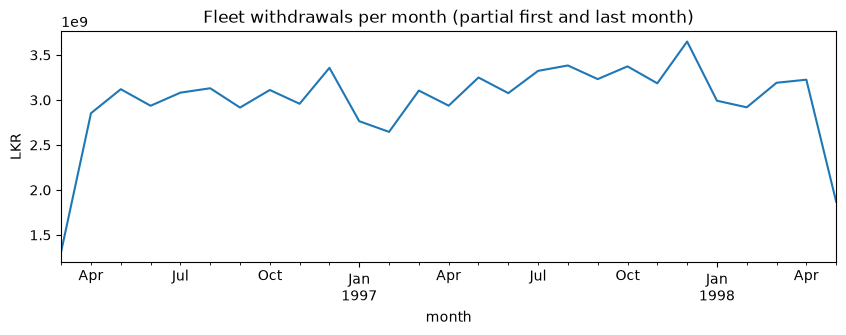

In [3]:
monthly = results["monthly_totals"]
ax = monthly.plot(x="month", y="total_withdrawals_lkr", legend=False, figsize=(10, 3))
ax.set(title="Fleet withdrawals per month (partial first and last month)", ylabel="LKR");

## Weekly and monthly patterns

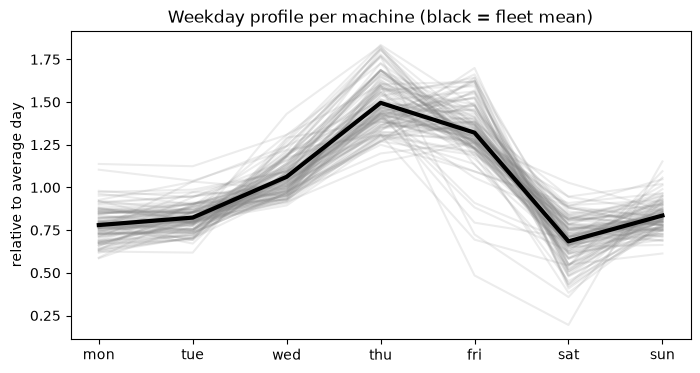

In [4]:
weekday = profiles.weekday_profile(df, normalize=True)
weekday.columns = [d[:3] for d in WEEKDAYS]
ax = weekday.T.plot(color="grey", alpha=0.15, legend=False, figsize=(8, 4))
weekday.mean().plot(ax=ax, color="black", linewidth=3)
ax.set(title="Weekday profile per machine (black = fleet mean)", ylabel="relative to average day");

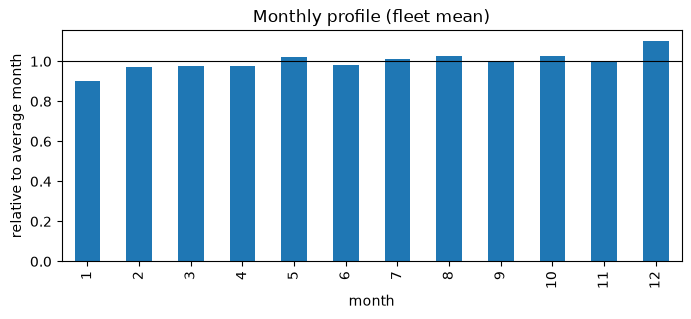

In [5]:
monthly_profile = profiles.monthly_profile(df, normalize=True).mean()
ax = monthly_profile.plot(kind="bar", figsize=(8, 3))
ax.axhline(1, color="black", linewidth=0.8)
ax.set(title="Monthly profile (fleet mean)", ylabel="relative to average month");

## Volatility, month-end and holidays

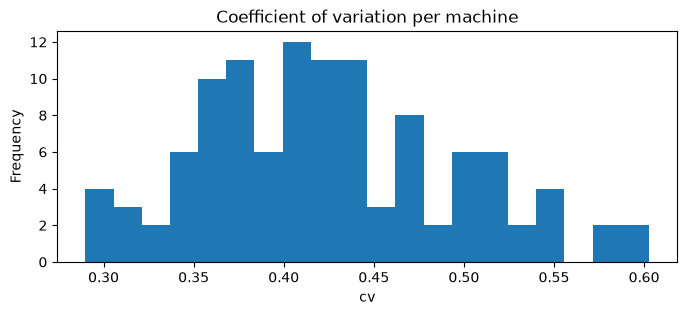

In [6]:
cv = profiles.coefficient_of_variation(df)
ax = cv.plot(kind="hist", bins=20, figsize=(8, 3))
ax.set(title="Coefficient of variation per machine", xlabel="cv");

In [7]:
month_end = profiles.month_end_effect(df)
print(f"median month-end ratio: {month_end.median():.2f}")

uk_holidays = holidays.country_holidays("GB", subdiv="ENG", years=range(1996, 1999))
profiles.holiday_effect(df, uk_holidays.keys())

median month-end ratio: 1.07


,offset,ratio,n_days
0,-1,0.708146,19
1,0,0.992817,19
2,1,0.896417,19


## Machine clusters

In [8]:
features = machine_features(df).join(clusters.set_index("machine_id"))
features.groupby(["cluster_id", "cluster_label"])[["cv", "level"]].agg(["mean", "count"])

cv               level      
                              mean count          mean count
cluster_id cluster_label                                    
0          steady         0.384170    56  8.544234e+05    56
1          volatile       0.463961    48  1.040280e+06    48
2          weekend_heavy  0.484351     7  6.404118e+05     7

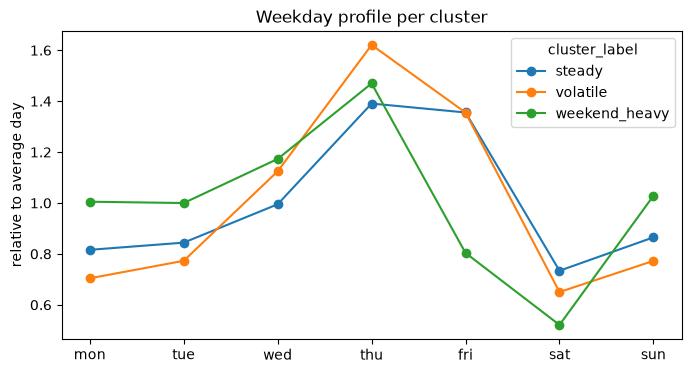

In [9]:
shape = features.groupby("cluster_label")[[f"wd_{d}" for d in range(7)]].mean()
shape.columns = [d[:3] for d in WEEKDAYS]
ax = shape.T.plot(marker="o", figsize=(8, 4))
ax.set(title="Weekday profile per cluster", ylabel="relative to average day");